In [7]:
df["GDP_Growth_Lag1"] = df["GDP_Growth"].shift(1)
df["GDP_Growth_Lag2"] = df["GDP_Growth"].shift(2)

df.head()

NameError: name 'df' is not defined

<Axes: xlabel='Year'>

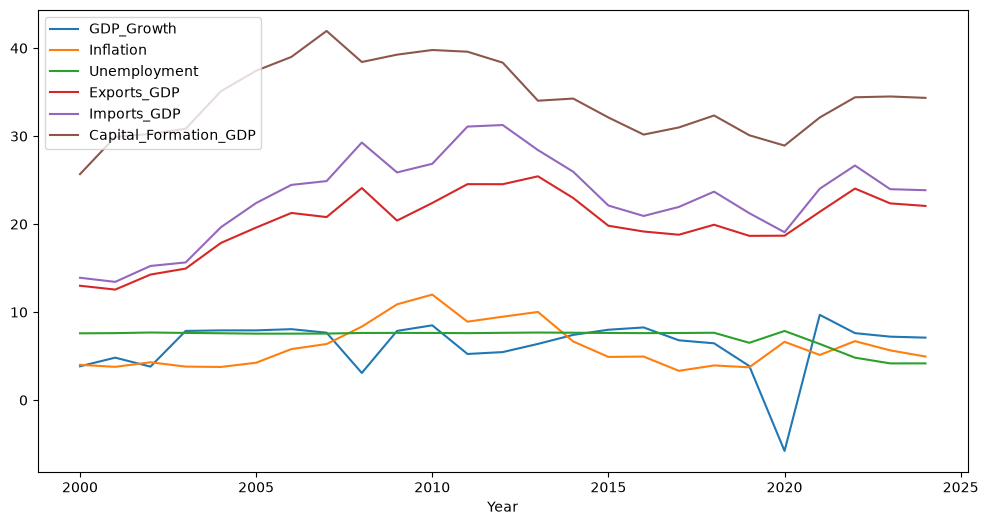

In [ ]:
df.plot(figsize=(12, 6))

In [ ]:
X = df.drop(columns=["GDP_Growth"])
y = df["GDP_Growth"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (23, 12)
Target shape: (23,)


In [ ]:
df.to_csv("../data/processed/india_economic_growth_features.csv")

print("Processed dataset saved successfully!")

Processed dataset saved successfully!


In [ ]:
df = df.dropna()

df.head()

,GDP_Growth,Inflation,Unemployment,Exports_GDP,Imports_GDP,Capital_Formation_GDP,GDP_Growth_Lag1,GDP_Growth_Lag2,Inflation_Lag1,Unemployment_Lag1,Exports_GDP_Lag1,Imports_GDP_Lag1,Capital_Formation_GDP_Lag1
Year,,,,,,,,,,,,,
2002,3.803975,4.297152,7.681,14.264384,15.244279,30.251300,4.823966,3.840991,3.779293,7.611,12.558380,13.434875,29.907889
2003,7.860381,3.805859,7.633,14.947914,15.644522,30.839700,3.803975,4.823966,4.297152,7.681,14.264384,15.244279,30.251300
2004,7.922937,3.767252,7.598,17.859125,19.644689,35.096492,7.860381,3.803975,3.805859,7.633,14.947914,15.644522,30.839700
2005,7.923431,4.246344,7.551,19.605247,22.396423,37.428264,7.922937,7.860381,3.767252,7.598,17.859125,19.644689,35.096492
2006,8.060733,5.796523,7.553,21.267941,24.456539,38.998506,7.923431,7.922937,4.246344,7.551,19.605247,22.396423,37.428264


In [ ]:
lag_columns = [
    "Inflation",
    "Unemployment",
    "Exports_GDP",
    "Imports_GDP",
    "Capital_Formation_GDP"
]

for col in lag_columns:
    df[f"{col}_Lag1"] = df[col].shift(1)

df.head()

,GDP_Growth,Inflation,Unemployment,Exports_GDP,Imports_GDP,Capital_Formation_GDP,GDP_Growth_Lag1,GDP_Growth_Lag2,Inflation_Lag1,Unemployment_Lag1,Exports_GDP_Lag1,Imports_GDP_Lag1,Capital_Formation_GDP_Lag1
Year,,,,,,,,,,,,,
2000,3.840991,4.009436,7.589,12.997236,13.903687,25.677317,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2001,4.823966,3.779293,7.611,12.558380,13.434875,29.907889,3.840991,NaN,4.009436,7.589,12.997236,13.903687,25.677317
2002,3.803975,4.297152,7.681,14.264384,15.244279,30.251300,4.823966,3.840991,3.779293,7.611,12.558380,13.434875,29.907889
2003,7.860381,3.805859,7.633,14.947914,15.644522,30.839700,3.803975,4.823966,4.297152,7.681,14.264384,15.244279,30.251300
2004,7.922937,3.767252,7.598,17.859125,19.644689,35.096492,7.860381,3.803975,3.805859,7.633,14.947914,15.644522,30.839700


In [ ]:
feature_columns = [
    "GDP_Growth_Lag1",
    "GDP_Growth_Lag2",
    "Inflation_Lag1",
    "Unemployment_Lag1",
    "Exports_GDP_Lag1",
    "Imports_GDP_Lag1",
    "Capital_Formation_GDP_Lag1"
]

X = df[feature_columns]
y = df["GDP_Growth"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print(X.head())

Features shape: (23, 7)
Target shape: (23,)
      GDP_Growth_Lag1  GDP_Growth_Lag2  Inflation_Lag1  Unemployment_Lag1  \
Year                                                                        
2002         4.823966         3.840991        3.779293              7.611   
2003         3.803975         4.823966        4.297152              7.681   
2004         7.860381         3.803975        3.805859              7.633   
2005         7.922937         7.860381        3.767252              7.598   
2006         7.923431         7.922937        4.246344              7.551   

      Exports_GDP_Lag1  Imports_GDP_Lag1  Capital_Formation_GDP_Lag1  
Year                                                                  
2002         12.558380         13.434875                   29.907889  
2003         14.264384         15.244279                   30.251300  
2004         14.947914         15.644522                   30.839700  
2005         17.859125         19.644689                   35

In [ ]:
train_size = int(len(X) * 0.8)

X_train = X.iloc[:train_size]
X_test = X.iloc[train_size:]

y_train = y.iloc[:train_size]
y_test = y.iloc[train_size:]

print("Training years:", X_train.index.min(), "to", X_train.index.max())
print("Testing years:", X_test.index.min(), "to", X_test.index.max())
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training years: 2002 to 2019
Testing years: 2020 to 2024
Training samples: 18
Testing samples: 5


In [ ]:
df.isnull().sum()

GDP_Growth                    0
Inflation                     0
Unemployment                  0
Exports_GDP                   0
Imports_GDP                   0
Capital_Formation_GDP         0
GDP_Growth_Lag1               1
GDP_Growth_Lag2               2
Inflation_Lag1                1
Unemployment_Lag1             1
Exports_GDP_Lag1              1
Imports_GDP_Lag1              1
Capital_Formation_GDP_Lag1    1
dtype: int64

<Axes: title={'center': 'India GDP Growth (2000–2024)'}, xlabel='Year'>

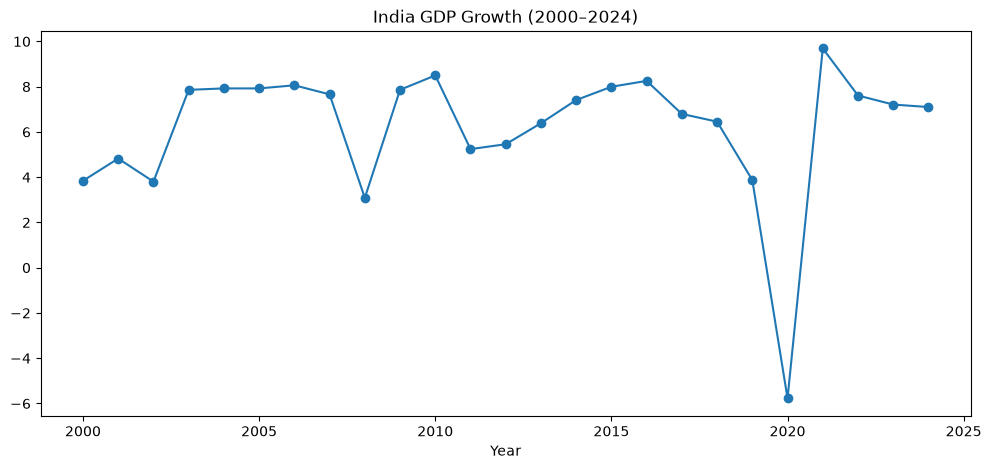

In [ ]:
df["GDP_Growth"].plot(
    figsize=(12, 5),
    title="India GDP Growth (2000–2024)",
    marker="o"
)

In [ ]:
df.isnull().sum()

GDP_Growth               0
Inflation                0
Unemployment             0
Exports_GDP              0
Imports_GDP              0
Capital_Formation_GDP    0
dtype: int64

In [ ]:
df.info()

<class 'pandas.DataFrame'>
Index: 25 entries, 2000 to 2024
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   GDP_Growth             25 non-null     float64
 1   Inflation              25 non-null     float64
 2   Unemployment           25 non-null     float64
 3   Exports_GDP            25 non-null     float64
 4   Imports_GDP            25 non-null     float64
 5   Capital_Formation_GDP  25 non-null     float64
dtypes: float64(6)
memory usage: 1.4 KB


In [8]:
import pandas as pd
import requests

# India
country = "IND"

# World Bank indicators
indicators = {
    "GDP_Growth": "NY.GDP.MKTP.KD.ZG",
    "Inflation": "FP.CPI.TOTL.ZG",
    "Unemployment": "SL.UEM.TOTL.ZS",
    "Exports_GDP": "NE.EXP.GNFS.ZS",
    "Imports_GDP": "NE.IMP.GNFS.ZS",
    "Capital_Formation_GDP": "NE.GDI.TOTL.ZS"
}

# Collect each indicator
data = {}

for name, indicator_code in indicators.items():
    url = (
        f"https://api.worldbank.org/v2/country/{country}/"
        f"indicator/{indicator_code}"
        f"?format=json&per_page=100"
    )

    response = requests.get(url)
    response.raise_for_status()

    json_data = response.json()[1]

    data[name] = {
        int(row["date"]): row["value"]
        for row in json_data
        if row["value"] is not None
    }

# Convert to DataFrame
df = pd.DataFrame(data)

# Sort by year
df.index.name = "Year"
df = df.sort_index()

# Keep a reasonable historical period
df = df.loc[1991:2025]

df.head()

,GDP_Growth,Inflation,Unemployment,Exports_GDP,Imports_GDP,Capital_Formation_GDP
Year,,,,,,
1991,1.056831,13.870246,7.641,8.494241,8.493486,25.140505
1992,5.482396,11.787817,7.649,8.842927,9.590172,27.440204
1993,4.750776,6.326890,7.662,9.834217,9.817322,22.716411
1994,6.658924,10.247936,7.593,9.888085,10.190059,26.310167
1995,7.574492,10.224886,7.570,10.843968,12.023481,29.152337


In [9]:
# Feature Engineering

df["GDP_Growth_Lag1"] = df["GDP_Growth"].shift(1)
df["GDP_Growth_Lag2"] = df["GDP_Growth"].shift(2)

lag_columns = [
    "Inflation",
    "Unemployment",
    "Exports_GDP",
    "Imports_GDP",
    "Capital_Formation_GDP"
]

for col in lag_columns:
    df[f"{col}_Lag1"] = df[col].shift(1)

df = df.dropna()

print("Feature engineering completed!")
print("First year:", df.index.min())
print("Last year:", df.index.max())
print("Total samples:", len(df))

Feature engineering completed!
First year: 1993
Last year: 2025
Total samples: 33


In [ ]:
feature_columns = [
    "GDP_Growth_Lag1",
    "GDP_Growth_Lag2",
    "Inflation_Lag1",
    "Unemployment_Lag1",
    "Exports_GDP_Lag1",
    "Imports_GDP_Lag1",
    "Capital_Formation_GDP_Lag1"
]

X = df[feature_columns]
y = df["GDP_Growth"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (33, 7)
Target shape: (33,)


In [12]:
train_size = int(len(X) * 0.8)

X_train = X.iloc[:train_size]
X_test = X.iloc[train_size:]
y_train = y.iloc[:train_size]
y_test = y.iloc[train_size:]

print("X:", X.shape)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Years:", X_train.index.min(), "-", X_train.index.max(),
      "|", X_test.index.min(), "-", X_test.index.max())

X: (33, 7)
X_train: (26, 7)
X_test: (7, 7)
Years: 1993 - 2018 | 2019 - 2025


In [11]:
# Rebuild features, target, and chronological split

feature_columns = [
    "GDP_Growth_Lag1",
    "GDP_Growth_Lag2",
    "Inflation_Lag1",
    "Unemployment_Lag1",
    "Exports_GDP_Lag1",
    "Imports_GDP_Lag1",
    "Capital_Formation_GDP_Lag1"
]

# Check required columns before proceeding
required_columns = feature_columns + ["GDP_Growth"]
missing = [col for col in required_columns if col not in df.columns]

if missing:
    print("Missing columns:", missing)
else:
    X = df[feature_columns].copy()
    y = df["GDP_Growth"].copy()

    train_size = int(len(X) * 0.8)

    X_train = X.iloc[:train_size]
    X_test = X.iloc[train_size:]
    y_train = y.iloc[:train_size]
    y_test = y.iloc[train_size:]

    print("X:", X.shape)
    print("X_train:", X_train.shape)
    print("X_test:", X_test.shape)
    print("Training years:", X_train.index.min(), "-", X_train.index.max())
    print("Testing years:", X_test.index.min(), "-", X_test.index.max())

X: (33, 7)
X_train: (26, 7)
X_test: (7, 7)
Training years: 1993 - 2018
Testing years: 2019 - 2025


In [ ]:
print("Economic Growth Forecasting System")
print("Python is working!")

Economic Growth Forecasting System
Python is working!


In [ ]:
df.isnull().sum()

GDP_Growth               0
Inflation                0
Unemployment             0
Exports_GDP              0
Imports_GDP              0
Capital_Formation_GDP    0
dtype: int64

In [ ]:
print("First year:", df.index.min())
print("Last year:", df.index.max())
print("Total years:", len(df))

First year: 1991
Last year: 2025
Total years: 35


In [ ]:
df["GDP_Growth_Lag1"] = df["GDP_Growth"].shift(1)
df["GDP_Growth_Lag2"] = df["GDP_Growth"].shift(2)

lag_columns = [
    "Inflation",
    "Unemployment",
    "Exports_GDP",
    "Imports_GDP",
    "Capital_Formation_GDP"
]

for col in lag_columns:
    df[f"{col}_Lag1"] = df[col].shift(1)

df.head()

,GDP_Growth,Inflation,Unemployment,Exports_GDP,Imports_GDP,Capital_Formation_GDP,GDP_Growth_Lag1,GDP_Growth_Lag2,Inflation_Lag1,Unemployment_Lag1,Exports_GDP_Lag1,Imports_GDP_Lag1,Capital_Formation_GDP_Lag1
Year,,,,,,,,,,,,,
1991,1.056831,13.870246,7.641,8.494241,8.493486,25.140505,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1992,5.482396,11.787817,7.649,8.842927,9.590172,27.440204,1.056831,NaN,13.870246,7.641,8.494241,8.493486,25.140505
1993,4.750776,6.326890,7.662,9.834217,9.817322,22.716411,5.482396,1.056831,11.787817,7.649,8.842927,9.590172,27.440204
1994,6.658924,10.247936,7.593,9.888085,10.190059,26.310167,4.750776,5.482396,6.326890,7.662,9.834217,9.817322,22.716411
1995,7.574492,10.224886,7.570,10.843968,12.023481,29.152337,6.658924,4.750776,10.247936,7.593,9.888085,10.190059,26.310167


In [ ]:
df = df.dropna()

df.to_csv("../data/processed/india_economic_growth_features.csv")

print("Final dataset:", df.index.min(), "to", df.index.max())
print("Total observations:", len(df))

Final dataset: 1993 to 2025
Total observations: 33


In [ ]:
feature_columns = [
    "GDP_Growth_Lag1",
    "GDP_Growth_Lag2",
    "Inflation_Lag1",
    "Unemployment_Lag1",
    "Exports_GDP_Lag1",
    "Imports_GDP_Lag1",
    "Capital_Formation_GDP_Lag1"
]

X = df[feature_columns]
y = df["GDP_Growth"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (33, 7)
Target: (33,)


In [ ]:
train_size = int(len(X) * 0.8)

X_train = X.iloc[:train_size]
X_test = X.iloc[train_size:]

y_train = y.iloc[:train_size]
y_test = y.iloc[train_size:]

print("Training:", X_train.index.min(), "to", X_train.index.max())
print("Testing:", X_test.index.min(), "to", X_test.index.max())
print("Train samples:", len(X_train))
print("Test samples:", len(X_test))

Training: 1993 to 2018
Testing: 2019 to 2025
Train samples: 26
Test samples: 7


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Baseline: next year's GDP growth = previous year's GDP growth
baseline_pred = X_test["GDP_Growth_Lag1"]

mae = mean_absolute_error(y_test, baseline_pred)
rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
r2 = r2_score(y_test, baseline_pred)

print("Naive Baseline")
print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

Naive Baseline
MAE : 4.393798524549416
RMSE: 7.007450129271815
R²  : -1.1299644940711713


In [ ]:
from sklearn.linear_model import LinearRegression

model_lr = LinearRegression()

model_lr.fit(X_train, y_train)

lr_pred = model_lr.predict(X_test)

mae_lr = mean_absolute_error(y_test, lr_pred)
rmse_lr = np.sqrt(mean_squared_error(y_test, lr_pred))
r2_lr = r2_score(y_test, lr_pred)

print("Linear Regression")
print("MAE :", mae_lr)
print("RMSE:", rmse_lr)
print("R²  :", r2_lr)

Linear Regression
MAE : 4.56688843132102
RMSE: 5.906738206594737
R²  : -0.5133792614818615


In [ ]:
from sklearn.ensemble import RandomForestRegressor

model_rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=5,
    random_state=42
)

model_rf.fit(X_train, y_train)

rf_pred = model_rf.predict(X_test)

mae_rf = mean_absolute_error(y_test, rf_pred)
rmse_rf = np.sqrt(mean_squared_error(y_test, rf_pred))
r2_rf = r2_score(y_test, rf_pred)

print("Random Forest")
print("MAE :", mae_rf)
print("RMSE:", rmse_rf)
print("R²  :", r2_rf)

Random Forest
MAE : 3.1892854323777207
RMSE: 4.988017199104817
R²  : -0.07921560696755803


In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

model_gb = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.03,
    max_depth=2,
    random_state=42
)

model_gb.fit(X_train, y_train)

gb_pred = model_gb.predict(X_test)

mae_gb = mean_absolute_error(y_test, gb_pred)
rmse_gb = np.sqrt(mean_squared_error(y_test, gb_pred))
r2_gb = r2_score(y_test, gb_pred)

print("Gradient Boosting")
print("MAE :", mae_gb)
print("RMSE:", rmse_gb)
print("R²  :", r2_gb)

Gradient Boosting
MAE : 3.7650695858033365
RMSE: 4.706049686293169
R²  : 0.03934964211117875


In [ ]:
from xgboost import XGBRegressor

print("XGBoost working!")

XGBoost working!


In [ ]:
feature_columns = [
    "GDP_Growth_Lag1",
    "GDP_Growth_Lag2",
    "Inflation_Lag1",
    "Unemployment_Lag1",
    "Exports_GDP_Lag1",
    "Imports_GDP_Lag1",
    "Capital_Formation_GDP_Lag1"
]

X = df[feature_columns]
y = df["GDP_Growth"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Feature columns:", list(X.columns))

Features shape: (31, 7)
Target shape: (31,)
Feature columns: ['GDP_Growth_Lag1', 'GDP_Growth_Lag2', 'Inflation_Lag1', 'Unemployment_Lag1', 'Exports_GDP_Lag1', 'Imports_GDP_Lag1', 'Capital_Formation_GDP_Lag1']


In [ ]:
train_size = int(len(X) * 0.8)

X_train = X.iloc[:train_size]
X_test = X.iloc[train_size:]

y_train = y.iloc[:train_size]
y_test = y.iloc[train_size:]

print("Training years:", X_train.index.min(), "to", X_train.index.max())
print("Testing years:", X_test.index.min(), "to", X_test.index.max())
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training years: 1995 to 2018
Testing years: 2019 to 2025
Training samples: 24
Testing samples: 7


In [ ]:
print("df:", len(df), df.index.min(), df.index.max())
print("X:", len(X), X.index.min(), X.index.max())
print("Missing values in X:", X.isna().sum().sum())
print("Missing values in y:", y.isna().sum())

df: 31 1995 2025
X: 31 1995 2025
Missing values in X: 0
Missing values in y: 0


In [14]:
train_size = int(len(X) * 0.8)

X_train = X.iloc[:train_size]
X_test = X.iloc[train_size:]

y_train = y.iloc[:train_size]
y_test = y.iloc[train_size:]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (26, 7)
X_test: (7, 7)
y_train: (26,)
y_test: (7,)


In [13]:
feature_columns = [
    "GDP_Growth_Lag1",
    "GDP_Growth_Lag2",
    "Inflation_Lag1",
    "Unemployment_Lag1",
    "Exports_GDP_Lag1",
    "Imports_GDP_Lag1",
    "Capital_Formation_GDP_Lag1"
]

X = df[feature_columns].copy()
y = df["GDP_Growth"].copy()

train_size = int(len(X) * 0.8)

X_train = X.iloc[:train_size]
X_test = X.iloc[train_size:]
y_train = y.iloc[:train_size]
y_test = y.iloc[train_size:]

print("X:", X.shape)
print("y:", y.shape)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X: (33, 7)
y: (33,)
X_train: (26, 7)
X_test: (7, 7)


In [15]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

models = {
    "Naive Baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "XGBoost": XGBRegressor(
        n_estimators=100,
        max_depth=2,
        learning_rate=0.03,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1
    )
}

print("All 5 models are ready!")

All 5 models are ready!


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values("MAE")

print("Model evaluation completed!")
display(results_df.round(3))

Model evaluation completed!


,Model,MAE,RMSE,R2
0,Naive Baseline,3.051,4.962,-0.068
2,Random Forest,3.167,4.993,-0.082
4,XGBoost,3.197,5.063,-0.112
3,Gradient Boosting,3.765,4.869,-0.028
1,Linear Regression,4.567,5.907,-0.513


In [17]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.metrics import make_scorer, mean_absolute_error

tscv = TimeSeriesSplit(n_splits=5)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X,
        y,
        cv=tscv,
        scoring=scoring
    )

    cv_results.append({
        "Model": name,
        "Mean MAE": -scores["test_MAE"].mean(),
        "Mean RMSE": -scores["test_RMSE"].mean(),
        "Mean R2": scores["test_R2"].mean()
    })

cv_df = pd.DataFrame(cv_results).sort_values("Mean MAE")

print("Time-series validation completed!")
display(cv_df.round(3))

Time-series validation completed!


,Model,Mean MAE,Mean RMSE,Mean R2
0,Naive Baseline,1.993,2.542,-0.804
4,XGBoost,2.624,3.323,-5.377
2,Random Forest,2.898,3.507,-9.863
3,Gradient Boosting,3.687,4.318,-23.596
1,Linear Regression,9.454,11.269,-172.139


In [34]:
# Select the best ML model using time-series cross-validation
# Exclude baseline because it is not an ML model

ml_cv_df = cv_df[cv_df["Model"] != "Naive Baseline"].copy()

best_model_name = ml_cv_df.iloc[0]["Model"]
best_model = models[best_model_name]

best_model.fit(X_train, y_train)

print("Best ML model:", best_model_name)
print("Cross-validation MAE:", round(ml_cv_df.iloc[0]["Mean MAE"], 3))

Best ML model: XGBoost
Cross-validation MAE: 2.624


In [19]:
print("Cross-validation ranking:")
display(cv_df.round(3))

print("\nHoldout test ranking:")
display(results_df.round(3))

print("\nTest period:", y_test.index.min(), "to", y_test.index.max())
print("Training period:", y_train.index.min(), "to", y_train.index.max())

Cross-validation ranking:


,Model,Mean MAE,Mean RMSE,Mean R2
0,Naive Baseline,1.993,2.542,-0.804
4,XGBoost,2.624,3.323,-5.377
2,Random Forest,2.898,3.507,-9.863
3,Gradient Boosting,3.687,4.318,-23.596
1,Linear Regression,9.454,11.269,-172.139



Holdout test ranking:


,Model,MAE,RMSE,R2
0,Naive Baseline,3.051,4.962,-0.068
2,Random Forest,3.167,4.993,-0.082
4,XGBoost,3.197,5.063,-0.112
3,Gradient Boosting,3.765,4.869,-0.028
1,Linear Regression,4.567,5.907,-0.513



Test period: 2019 to 2025
Training period: 1993 to 2018


In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

baseline_predictions = X_test["GDP_Growth_Lag1"]

baseline_results = pd.DataFrame({
    "Year": y_test.index,
    "Actual_GDP_Growth": y_test.values,
    "Baseline_Prediction": baseline_predictions.values
})

baseline_results["Absolute_Error"] = abs(
    baseline_results["Actual_GDP_Growth"]
    - baseline_results["Baseline_Prediction"]
)

print(
    "Last-year baseline MAE:",
    round(
        mean_absolute_error(y_test, baseline_predictions),
        3
    )
)

print(
    "Last-year baseline RMSE:",
    round(
        np.sqrt(mean_squared_error(y_test, baseline_predictions)),
        3
    )
)

display(baseline_results.round(3))

Last-year baseline MAE: 4.394
Last-year baseline RMSE: 7.007


,Year,Actual_GDP_Growth,Baseline_Prediction,Absolute_Error
0,2019,3.871,6.454,2.582
1,2020,-5.778,3.871,9.649
2,2021,9.690,-5.778,15.467
3,2022,7.609,9.690,2.080
4,2023,7.210,7.609,0.399
5,2024,7.099,7.210,0.111
6,2025,7.567,7.099,0.467


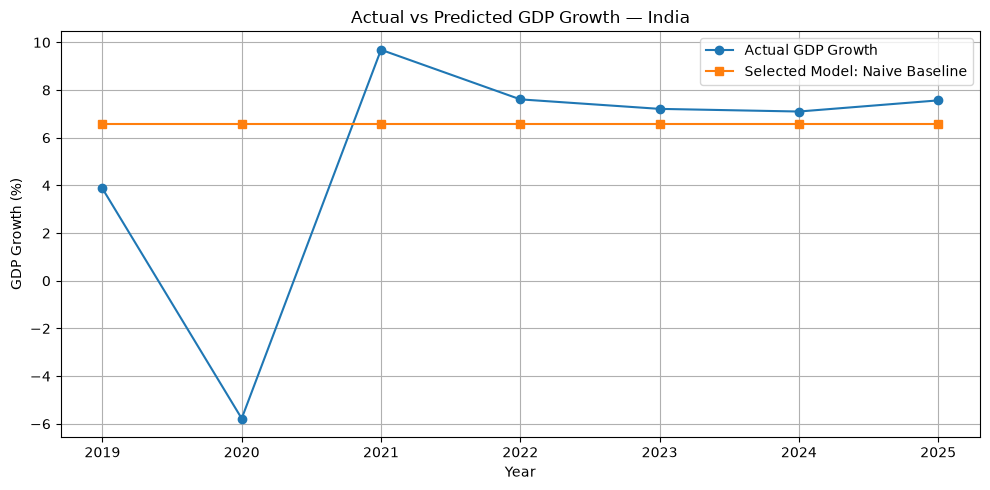

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    y_test.index,
    y_test.values,
    marker="o",
    label="Actual GDP Growth"
)

plt.plot(
    y_test.index,
    predictions,
    marker="s",
    label=f"Selected Model: {best_model_name}"
)

plt.xlabel("Year")
plt.ylabel("GDP Growth (%)")
plt.title("Actual vs Predicted GDP Growth — India")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [22]:
print("Latest year:", df.index.max())
print("Latest GDP growth:", df["GDP_Growth"].iloc[-1])
print("Feature columns:", list(X.columns))
print("Missing values:", X.isna().sum().sum())

Latest year: 2025
Latest GDP growth: 7.56666179284244
Feature columns: ['GDP_Growth_Lag1', 'GDP_Growth_Lag2', 'Inflation_Lag1', 'Unemployment_Lag1', 'Exports_GDP_Lag1', 'Imports_GDP_Lag1', 'Capital_Formation_GDP_Lag1']
Missing values: 0


In [23]:
# Prepare the latest available features for forecasting

latest_features = X.iloc[[-1]].copy()

print("Forecast input year:", latest_features.index[0])
print("Number of features:", latest_features.shape[1])
print("Missing values:", latest_features.isna().sum().sum())

Forecast input year: 2025
Number of features: 7
Missing values: 0


In [26]:
import joblib
from pathlib import Path

model_path = Path("../models/best_model.joblib")
joblib.dump(best_model, model_path)

print("Model saved:", model_path)
print("Selected model:", best_model_name)

Model saved: ../models/best_model.joblib
Selected model: XGBoost


In [27]:

# Forecast next year's GDP growth using the latest available features

forecast_input = X.iloc[[-1]].copy()
forecast_value = best_model.predict(forecast_input)[0]

forecast_year = int(df.index.max()) + 1

print("Country: India")
print("Forecast year:", forecast_year)
print("Predicted GDP growth (%):", round(float(forecast_value), 2))
print("Selected model:", best_model_name)


Country: India
Forecast year: 2026
Predicted GDP growth (%): 6.82
Selected model: XGBoost


In [35]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

predictions = best_model.predict(X_test)

print("Model:", best_model_name)
print("Holdout MAE:", round(mean_absolute_error(y_test, predictions), 3))
print("Holdout RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 3))

print("Baseline MAE:", round(mean_absolute_error(
    y_test, X_test["GDP_Growth_Lag1"]
), 3))

Model: XGBoost
Holdout MAE: 3.197
Holdout RMSE: 5.063
Baseline MAE: 4.394


In [36]:
import pandas as pd
from pathlib import Path

forecast_input = X.iloc[[-1]].copy()
forecast_value = best_model.predict(forecast_input)[0]
forecast_year = int(df.index.max()) + 1

forecast_df = pd.DataFrame({
    "Country": ["India"],
    "Forecast_Year": [forecast_year],
    "Predicted_GDP_Growth_Percent": [round(float(forecast_value), 2)],
    "Model": [best_model_name]
})

output_path = Path("../data/processed/india_gdp_forecast.csv")
forecast_df.to_csv(output_path, index=False)

display(forecast_df)
print("Forecast saved to:", output_path)

,Country,Forecast_Year,Predicted_GDP_Growth_Percent,Model
0,India,2026,6.82,XGBoost


Forecast saved to: ../data/processed/india_gdp_forecast.csv


In [28]:

# Compare ML models against the naive baseline

baseline_mae = cv_df.loc[
    cv_df["Model"] == "Naive Baseline", "Mean MAE"
].iloc[0]

best_ml = cv_df[cv_df["Model"] != "Naive Baseline"].iloc[0]

print("Baseline MAE:", round(baseline_mae, 3))
print("Best ML model:", best_ml["Model"])
print("Best ML MAE:", round(best_ml["Mean MAE"], 3))

if best_ml["Mean MAE"] < baseline_mae:
    print("Result: ML model beats the baseline.")
else:
    print("Result: ML model does not beat the baseline yet.")


Baseline MAE: 1.993
Best ML model: XGBoost
Best ML MAE: 2.624
Result: ML model does not beat the baseline yet.


In [33]:
# Compare models using chronological holdout results

display(results_df.round(3))

print("Cross-validation winner:", cv_df.iloc[0]["Model"])
print("Holdout winner:", results_df.iloc[0]["Model"])

,Model,MAE,RMSE,R2
0,Naive Baseline,3.051,4.962,-0.068
2,Random Forest,3.167,4.993,-0.082
4,XGBoost,3.197,5.063,-0.112
3,Gradient Boosting,3.765,4.869,-0.028
1,Linear Regression,4.567,5.907,-0.513


Cross-validation winner: Naive Baseline
Holdout winner: Naive Baseline


In [31]:
print("Selected model:", best_model_name)
print("Latest data year:", df.index.max())
print("Cross-validation winner:", cv_df.iloc[0]["Model"])

Selected model: XGBoost
Latest data year: 2025
Cross-validation winner: Naive Baseline
